# Анализ лояльности пользователей Яндекс Афиши

Команда маркетинга Яндекс Афиши хочет понять, какие пользователи с большей вероятностью возвращаются на платформу и делают повторные заказы. Результаты помогут выявлять перспективных клиентов, точнее настраивать рекламу, оптимизировать маркетинговый бюджет и повышать удержание.

**Цель:** изучить заказы пользователей за июнь–октябрь 2024 года, построить профиль каждого пользователя и найти признаки, которые связаны с повторными покупками.

**План работы:**
1. Загрузка данных и знакомство с ними
2. Предобработка данных
3. Создание профиля пользователя
4. Исследовательский анализ данных
5. Общие выводы и рекомендации

## 1. Загрузка данных и знакомство с ними

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from phik import phik_matrix
from dotenv import load_dotenv

In [2]:
load_dotenv()

db_config = {
    'user': os.getenv('DB_USER'),
    'pwd': os.getenv('DB_PASSWORD'),
    'host': os.getenv('DB_HOST'),
    'port': os.getenv('DB_PORT'),
    'db': os.getenv('DB_NAME')
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

query = '''
SELECT p.user_id,
       p.device_type_canonical,
       p.order_id,
       p.created_dt_msk AS order_dt,
       p.created_ts_msk AS order_ts,
       p.currency_code,
       p.revenue,
       p.tickets_count,
       p.created_dt_msk::date - LAG(p.created_dt_msk::date) OVER (PARTITION BY p.user_id ORDER BY p.created_dt_msk) AS days_since_prev,
       p.event_id,
       e.event_name_code AS event_name,
       e.event_type_main,
       p.service_name,
       r.region_name,
       c.city_name
FROM afisha.purchases AS p
JOIN afisha.events AS e ON p.event_id = e.event_id
JOIN afisha.city AS c ON e.city_id = c.city_id
JOIN afisha.regions AS r ON c.region_id = r.region_id
WHERE p.device_type_canonical IN ('mobile', 'desktop')
  AND e.event_type_main != 'фильм'
ORDER BY p.user_id
'''

In [3]:
try:
    engine = create_engine(connection_string, connect_args={'connect_timeout': 10})
    df = pd.read_sql_query(query, con=engine)
    print('Данные загружены из базы данных')
except Exception:
    orders = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_orders_df.csv')
    events = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_events_df.csv')
    df = orders.merge(events, on='event_id', how='inner')
    df = df.rename(columns={'created_dt_msk': 'order_dt', 'created_ts_msk': 'order_ts'})
    df = df[['user_id', 'device_type_canonical', 'order_id', 'order_dt', 'order_ts', 'currency_code',
             'revenue', 'tickets_count', 'days_since_prev', 'event_id', 'event_name', 'event_type_main',
             'service_name', 'region_name', 'city_name']]
    df = df.sort_values(by='user_id').reset_index(drop=True)
    print('База данных недоступна, данные загружены из CSV-выгрузки Практикума')

База данных недоступна, данные загружены из CSV-выгрузки Практикума


Параметры подключения к базе хранятся в файле `.env` и не попадают в репозиторий. Подключение к базе может быть недоступно из некоторых сетей. Поэтому, если база не отвечает, данные загружаются из CSV-выгрузки тех же таблиц на сервере Практикума. Таблицы заказов и мероприятий соединяются по `event_id`, как в SQL-запросе, а нужные поля переименовываются так же.

In [4]:
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   user_id                290611 non-null  str    
 1   device_type_canonical  290611 non-null  str    
 2   order_id               290611 non-null  int64  
 3   order_dt               290611 non-null  str    
 4   order_ts               290611 non-null  str    
 5   currency_code          290611 non-null  str    
 6   revenue                290611 non-null  float64
 7   tickets_count          290611 non-null  int64  
 8   days_since_prev        268698 non-null  float64
 9   event_id               290611 non-null  int64  
 10  event_name             290611 non-null  str    
 11  event_type_main        290611 non-null  str    
 12  service_name           290611 non-null  str    
 13  region_name            290611 non-null  str    
 14  city_name              290611 non-null  str    

**Вывод по загрузке.** Получено 290 611 заказов и 15 столбцов, состав столбцов соответствует описанию выгрузки. Данные охватывают заказы с 1 июня по 31 октября 2024 года, только с мобильных и десктопных устройств и без заказов на фильмы.

Что нужно сделать на предобработке:
- `order_dt` и `order_ts` хранятся как строки, их нужно привести к типу datetime;
- целочисленные и дробные столбцы (`tickets_count`, `order_id`, `event_id`, `days_since_prev`) можно перевести в более компактные типы;
- пропуски есть только в `days_since_prev`, как и ожидалось;
- выручка указана в двух валютах (`rub` и `kzt`), её нужно привести к рублям;
- нужно проверить дубликаты, категориальные значения и выбросы в выручке и количестве билетов.

## 2. Предобработка данных

### 2.1. Приведение выручки к рублям

In [6]:
tenge = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')
tenge.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [7]:
df['currency_code'].value_counts()

currency_code
rub    285542
kzt      5069
Name: count, dtype: int64

In [8]:
tenge['data'] = pd.to_datetime(tenge['data'])
df['order_dt'] = pd.to_datetime(df['order_dt'])
df['order_ts'] = pd.to_datetime(df['order_ts'])

df = df.merge(tenge[['data', 'curs']], left_on='order_dt', right_on='data', how='left')

df['revenue_rub'] = df['revenue']
df.loc[df['currency_code'] == 'kzt', 'revenue_rub'] = df['revenue'] * df['curs'] / 100

df = df.drop(columns=['data', 'curs'])

print(df.loc[df['currency_code'] == 'kzt', 'revenue_rub'].isna().sum())
df.groupby('currency_code')[['revenue', 'revenue_rub']].mean().round(2)

0


,revenue,revenue_rub
currency_code,,
kzt,4995.21,981.33
rub,548.01,548.01


В тенге оплачено 5 069 заказов (1,7%). Для них выручка пересчитана по курсу на дату заказа: курс дан за 100 тенге, поэтому сумма умножается на курс и делится на 100. Курс нашёлся для всех дат заказов, пропусков в `revenue_rub` нет. После пересчёта средняя выручка с заказа в тенге составила 981 руб. против 548 руб. в рублёвых заказах. Для рублёвых заказов `revenue_rub` совпадает с `revenue`.

### 2.2. Пропуски, типы данных, дубликаты и выбросы

In [9]:
missing = pd.DataFrame({
    'количество': df.isna().sum(),
    'доля, %': (df.isna().mean() * 100).round(2)
})
missing

,количество,"доля, %"
user_id,0,0.00
device_type_canonical,0,0.00
order_id,0,0.00
order_dt,0,0.00
order_ts,0,0.00
currency_code,0,0.00
revenue,0,0.00
tickets_count,0,0.00
days_since_prev,21913,7.54
event_id,0,0.00


In [10]:
print(df['days_since_prev'].isna().sum())
print(df['user_id'].nunique())

21913
21933


Пропуски есть только в `days_since_prev`: 21 913 значений (7,5%). Это первые покупки пользователей, у которых нет предыдущего заказа. Число пропусков почти совпадает с числом пользователей (21 933). Небольшая разница связана с тем, что интервал считался по всем заказам пользователя, включая отфильтрованные. Пропуски оставляем: заменить их нечем, и при расчёте среднего интервала они просто не учитываются.

In [11]:
df['tickets_count'] = pd.to_numeric(df['tickets_count'], downcast='integer')
df['order_id'] = pd.to_numeric(df['order_id'], downcast='integer')
df['event_id'] = pd.to_numeric(df['event_id'], downcast='integer')
df['revenue'] = pd.to_numeric(df['revenue'], downcast='float')
df['revenue_rub'] = pd.to_numeric(df['revenue_rub'], downcast='float')
df['days_since_prev'] = pd.to_numeric(df['days_since_prev'], downcast='float')
df.dtypes

user_id                             str
device_type_canonical               str
order_id                          int32
order_dt                 datetime64[us]
order_ts                 datetime64[us]
currency_code                       str
revenue                         float64
tickets_count                      int8
days_since_prev                 float32
event_id                          int32
event_name                          str
event_type_main                     str
service_name                        str
region_name                         str
city_name                           str
revenue_rub                     float64
dtype: object

Даты приведены к datetime, а числовые столбцы — к более компактным типам: `tickets_count` теперь int8, `order_id` и `event_id` — int32, `days_since_prev` — float32. Это уменьшает объём памяти и не влияет на значения.

In [12]:
for column in ['device_type_canonical', 'currency_code', 'event_type_main']:
    print(df[column].value_counts(), end='\n\n')

device_type_canonical
mobile     232490
desktop     58121
Name: count, dtype: int64

currency_code
rub    285542
kzt      5069
Name: count, dtype: int64

event_type_main
концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: count, dtype: int64



In [13]:
print(df['service_name'].nunique())
print(sorted(df['service_name'].unique()))

36
['Crazy ticket!', 'Show_ticket', 'Билет по телефону', 'Билеты без проблем', 'Билеты в интернете', 'Билеты в руки', 'Быстробилет', 'Быстрый кассир', 'Весь в билетах', 'Восьмёрка', 'Вперёд!', 'Выступления.ру', 'Городской дом культуры', 'Дом культуры', 'Дырокол', 'За билетом!', 'Зе Бест!', 'КарандашРУ', 'Кино билет', 'Край билетов', 'Лимоны', 'Лови билет!', 'Лучшие билеты', 'Мир касс', 'Мой билет', 'Облачко', 'Прачечная', 'Радио ticket', 'Реестр', 'Росбилет', 'Тебе билет!', 'Телебилет', 'Тех билет', 'Цвет и билет', 'Шоу начинается!', 'Яблоко']


In [14]:
print(df['region_name'].nunique(), df['city_name'].nunique())
df['region_name'].value_counts().head(10)

81 352


region_name
Каменевский регион         91058
Североярская область       44049
Широковская область        16457
Медовская область          13901
Озернинский край           10476
Светополянский округ        7607
Малиновоярский округ        6618
Речиновская область         6293
Солнечноземская область     6288
Яблоневская область         6181
Name: count, dtype: int64

**Категориальные данные:**
- в `device_type_canonical` только `mobile` и `desktop`, в `currency_code` — `rub` и `kzt`;
- в `event_type_main` 7 категорий. Категория «другое» — это отдельный тип мероприятий, а не обозначение пропуска;
- 36 билетных операторов, 81 регион и 352 города. Значений вроде «нет данных», «unknown» или пустых строк не обнаружено, неявных дубликатов в написании нет, поэтому нормализация не нужна.

In [15]:
print(df['order_id'].duplicated().sum())
print(df.drop(columns='order_id').duplicated().sum())

0


30


In [16]:
rows_start = df.shape[0]

df = df.drop_duplicates(subset=[col for col in df.columns if col != 'order_id'])
df.shape[0]

290581

Повторов `order_id` нет. Но нашлось 30 заказов, которые полностью совпадают по всем полям, кроме номера: тот же пользователь, то же мероприятие, время до секунды, сумма и количество билетов. Скорее всего, это техническое дублирование заказа, поэтому такие строки удалены.

In [17]:
df[['revenue_rub', 'tickets_count']].describe()

,revenue_rub,tickets_count
count,290581.000000,290581.000000
mean,555.594726,2.754337
std,875.529616,1.170614
min,-90.760000,1.000000
25%,113.970000,2.000000
50%,351.140000,3.000000
75%,802.050000,4.000000
max,81174.540000,57.000000


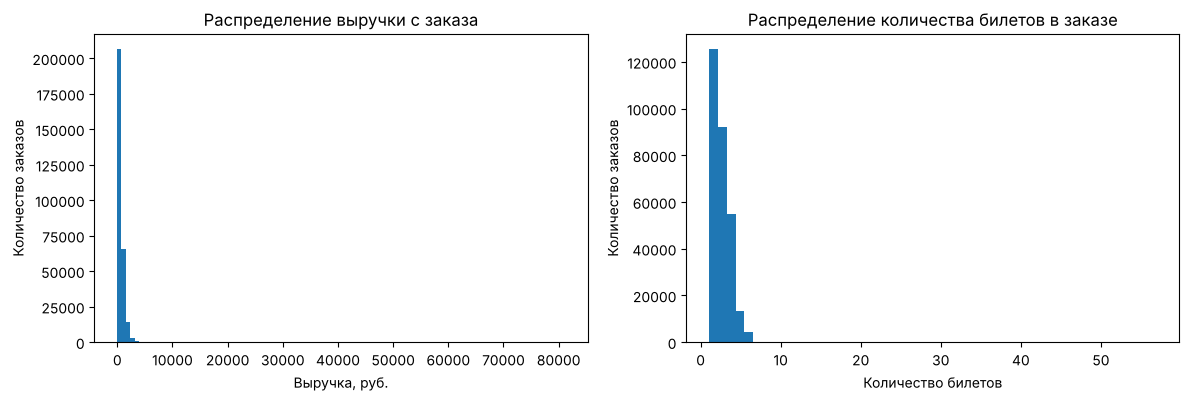

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df['revenue_rub'].plot(kind='hist', bins=100, ax=axes[0])
axes[0].set_title('Распределение выручки с заказа')
axes[0].set_xlabel('Выручка, руб.')
axes[0].set_ylabel('Количество заказов')

df['tickets_count'].plot(kind='hist', bins=50, ax=axes[1])
axes[1].set_title('Распределение количества билетов в заказе')
axes[1].set_xlabel('Количество билетов')
axes[1].set_ylabel('Количество заказов')

plt.show()

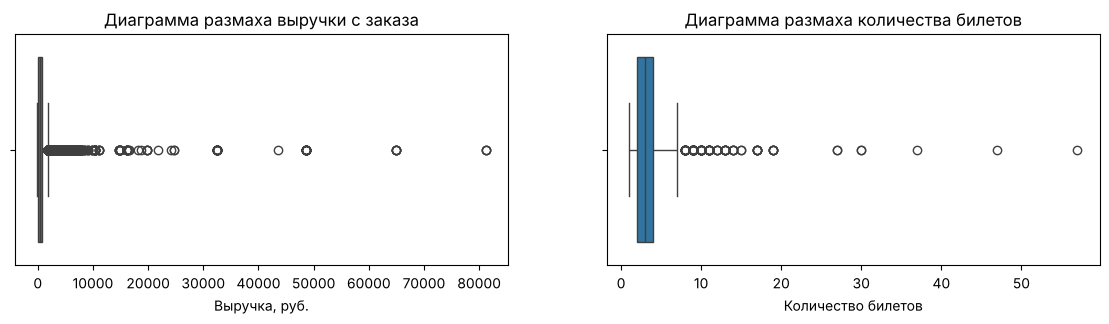

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

sns.boxplot(x=df['revenue_rub'], ax=axes[0])
axes[0].set_title('Диаграмма размаха выручки с заказа')
axes[0].set_xlabel('Выручка, руб.')

sns.boxplot(x=df['tickets_count'], ax=axes[1])
axes[1].set_title('Диаграмма размаха количества билетов')
axes[1].set_xlabel('Количество билетов')

plt.show()

In [20]:
print((df['revenue_rub'] < 0).sum())
print((df['revenue_rub'] == 0).sum())
print(df['revenue_rub'].quantile(0.99))

381
5525
2628.4217390400004


In [21]:
revenue_99 = df['revenue_rub'].quantile(0.99)

df = df[(df['revenue_rub'] >= 0) & (df['revenue_rub'] <= revenue_99)]
df = df.reset_index(drop=True)

rows_end = df.shape[0]
print('Было строк:', rows_start)
print('Осталось строк:', rows_end)
print('Удалено строк:', rows_start - rows_end)
print('Доля удалённых строк:', round((rows_start - rows_end) / rows_start * 100, 2), '%')

Было строк: 290611
Осталось строк: 287375
Удалено строк: 3236
Доля удалённых строк: 1.11 %


In [22]:
df[['revenue_rub', 'tickets_count']].describe()

,revenue_rub,tickets_count
count,287375.000000,287375.000000
mean,518.738402,2.741348
std,511.956308,1.163080
min,0.000000,1.000000
25%,112.640000,2.000000
50%,344.840000,3.000000
75%,788.900000,3.000000
max,2628.421739,57.000000


**Выбросы:**
- в `revenue_rub` есть 381 отрицательное значение (возможно, возвраты или корректировки) и длинный хвост дорогих заказов до 81 тыс. руб.; 99-й перцентиль — 2 628 руб.;
- в `tickets_count` медиана — 3 билета, максимум — 57; такие заказы редкие (групповые покупки), их оставляем, потому что они не искажают средние значения.

Заказы с отрицательной выручкой и выручкой выше 99-го перцентиля удалены.

**Промежуточный вывод по предобработке:**
- выручка приведена к рублям, добавлен столбец `revenue_rub`;
- даты приведены к datetime, числовые столбцы — к компактным типам;
- пропуски есть только в `days_since_prev` у первых покупок, они оставлены;
- удалено 30 дубликатов и заказы с выручкой меньше 0 или выше 99-го перцентиля;
- всего удалено 3 236 строк (1,11%), осталось 287 375 заказов.

## 3. Создание профиля пользователя

### 3.1. Профиль пользователя

In [23]:
df = df.sort_values(by=['user_id', 'order_ts'])

profile = df.groupby('user_id').agg(
    first_dt=('order_dt', 'min'),
    last_dt=('order_dt', 'max'),
    first_device=('device_type_canonical', 'first'),
    first_region=('region_name', 'first'),
    first_service=('service_name', 'first'),
    first_event_type=('event_type_main', 'first'),
    total_orders=('order_id', 'count'),
    avg_revenue_rub=('revenue_rub', 'mean'),
    avg_tickets_count=('tickets_count', 'mean'),
    avg_days_since_prev=('days_since_prev', 'mean')
).reset_index()

profile['is_two'] = (profile['total_orders'] >= 2).astype(int)
profile['is_five'] = (profile['total_orders'] >= 5).astype(int)

profile.head()

,user_id,first_dt,last_dt,first_device,first_region,first_service,first_event_type,total_orders,avg_revenue_rub,avg_tickets_count,avg_days_since_prev,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,Край билетов,театр,1,1521.940000,4.000000,NaN,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,Мой билет,выставки,2,774.010000,3.000000,75.0,1,0
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,Лови билет!,другое,3,767.213333,2.666667,51.0,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,Край билетов,театр,1,917.830000,4.000000,NaN,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,Лучшие билеты,театр,2,61.310000,1.500000,16.0,1,0


Для каждого пользователя посчитаны даты первого и последнего заказа, признаки первого заказа (устройство, регион, билетный оператор, тип мероприятия), общее число заказов, средняя выручка с заказа, среднее число билетов и среднее число дней между заказами. Признаки `is_two` и `is_five` показывают, сделал ли пользователь 2 и более и 5 и более заказов соответственно.

### 3.2. Проверка данных профилей

In [24]:
print('Пользователей:', profile.shape[0])
print('Средняя выручка с заказа:', round(df['revenue_rub'].mean(), 2))
print('Доля пользователей с 2+ заказами:', round(profile['is_two'].mean(), 3))
print('Доля пользователей с 5+ заказами:', round(profile['is_five'].mean(), 3))

Пользователей: 21838
Средняя выручка с заказа: 518.74
Доля пользователей с 2+ заказами: 0.617
Доля пользователей с 5+ заказами: 0.29


In [25]:
profile[['total_orders', 'avg_tickets_count', 'avg_days_since_prev']].describe()

,total_orders,avg_tickets_count,avg_days_since_prev
count,21838.000000,21838.000000,13510.000000
mean,13.159401,2.744071,15.873504
std,121.565018,0.913081,22.324905
min,1.000000,1.000000,0.000000
25%,1.000000,2.000000,1.000000
50%,2.000000,2.750000,8.000000
75%,5.000000,3.080000,20.500000
max,10168.000000,11.000000,148.000000


In [26]:
print(profile['total_orders'].quantile([0.9, 0.95, 0.99]))
profile.sort_values(by='total_orders', ascending=False).head()

0.90     15.0
0.95     31.0
0.99    152.0
Name: total_orders, dtype: float64


,user_id,first_dt,last_dt,first_device,first_region,first_service,first_event_type,total_orders,avg_revenue_rub,avg_tickets_count,avg_days_since_prev,is_two,is_five
981,0beb8fc0c0a9ce1,2024-06-01,2024-10-31,mobile,Североярская область,Билеты в руки,концерты,10168,505.802102,2.863297,0.014950,1,1
2054,18e9aead0a393e7,2024-06-01,2024-10-31,mobile,Каменевский регион,Облачко,концерты,4346,495.398145,2.789692,0.034753,1,1
11069,8187dac4be757a0,2024-06-01,2024-10-31,mobile,Берёзовская область,Билеты в руки,концерты,4014,538.360585,2.748879,0.036382,1,1
5413,3ee7dc2e115847f,2024-06-01,2024-10-31,mobile,Каменевский регион,Мой билет,концерты,3785,537.793480,2.764861,0.039641,1,1
10806,7eb4fc207ecc10f,2024-06-01,2024-10-31,mobile,Каменевский регион,Билеты без проблем,театр,3706,543.071223,2.957906,0.040486,1,1


В выборке 21 838 пользователей. 61,7% из них сделали 2 и более заказа, 29% — 5 и более. Средняя выручка с заказа — 519 руб.

Объём данных достаточный для анализа. Но в числе заказов есть явные аномалии: медиана — 2 заказа, 99-й перцентиль — 152, а максимум — 10 168 заказов за 5 месяцев, со средним интервалом меньше часа. Такие аккаунты похожи на перекупщиков, корпоративных клиентов или технические учётные записи, а не на обычных зрителей. Они сильно искажают средние значения, поэтому отфильтруем пользователей по 99-му перцентилю числа заказов.

Среднее количество билетов в заказе (от 1 до 11, медиана 2,75) аномалий не содержит.

In [27]:
orders_99 = profile['total_orders'].quantile(0.99)
users_start = profile.shape[0]

profile = profile[profile['total_orders'] <= orders_99].reset_index(drop=True)

print('Удалено пользователей:', users_start - profile.shape[0])
print('Доля удалённых пользователей:', round((users_start - profile.shape[0]) / users_start * 100, 2), '%')

Удалено пользователей: 216
Доля удалённых пользователей: 0.99 %


In [28]:
print('Пользователей:', profile.shape[0])
print('Доля пользователей с 2+ заказами:', round(profile['is_two'].mean(), 3))
print('Доля пользователей с 5+ заказами:', round(profile['is_five'].mean(), 3))
profile[['total_orders', 'avg_revenue_rub', 'avg_tickets_count', 'avg_days_since_prev']].describe()

Пользователей: 21622
Доля пользователей с 2+ заказами: 0.613
Доля пользователей с 5+ заказами: 0.283


,total_orders,avg_revenue_rub,avg_tickets_count,avg_days_since_prev
count,21622.000000,21622.000000,21622.000000,13294.000000
mean,6.496069,545.346749,2.744265,16.123960
std,14.308967,433.545756,0.917489,22.418186
min,1.000000,0.000000,1.000000,0.000000
25%,1.000000,211.057500,2.000000,1.333333
50%,2.000000,464.656597,2.750000,8.379807
75%,5.000000,768.573333,3.100000,20.851191
max,152.000000,2628.421739,11.000000,148.000000


Удалено 216 пользователей (0,99%). После фильтрации осталось 21 622 пользователя: 61,3% сделали 2 и более заказа, 28,3% — 5 и более. Среднее число заказов снизилось с 13,2 до 6,5 при медиане 2, средняя выручка с заказа — 545 руб., среднее количество билетов — 2,74, средний интервал между заказами — 16 дней (медиана 8).

## 4. Исследовательский анализ данных

### 4.1. Признаки первого заказа и возврат пользователей

#### 4.1.1. Распределение пользователей по признакам первого заказа

In [29]:
def segment_table(column):
    table = profile.groupby(column).agg(users=('user_id', 'count'), return_share=('is_two', 'mean'))
    table['users_share'] = table['users'] / table['users'].sum()
    table = table.sort_values(by='users', ascending=False)
    return table[['users', 'users_share', 'return_share']].round(3)

In [30]:
segment_table('first_event_type')

,users,users_share,return_share
first_event_type,,,
концерты,9564,0.442,0.618
другое,5401,0.250,0.596
театр,4245,0.196,0.634
стендап,1110,0.051,0.609
спорт,794,0.037,0.558
выставки,413,0.019,0.642
ёлки,95,0.004,0.558


In [31]:
segment_table('first_device')

,users,users_share,return_share
first_device,,,
mobile,17906,0.828,0.608
desktop,3716,0.172,0.638


In [32]:
region_table = segment_table('first_region')
print(region_table.shape[0])
region_table.head(10)

81


,users,users_share,return_share
first_region,,,
Каменевский регион,7086,0.328,0.624
Североярская область,3768,0.174,0.638
Широковская область,1223,0.057,0.644
Озернинский край,675,0.031,0.553
Малиновоярский округ,526,0.024,0.559
Шанырский регион,502,0.023,0.673
Травяная область,488,0.023,0.615
Светополянский округ,457,0.021,0.656
Речиновская область,440,0.020,0.634


In [33]:
service_table = segment_table('first_service')
print(service_table.shape[0])
service_table.head(10)

34


,users,users_share,return_share
first_service,,,
Билеты без проблем,5167,0.239,0.603
Мой билет,2970,0.137,0.609
Лови билет!,2812,0.130,0.610
Билеты в руки,2557,0.118,0.628
Облачко,2177,0.101,0.612
Весь в билетах,1286,0.059,0.629
Лучшие билеты,1182,0.055,0.613
Прачечная,583,0.027,0.626
Край билетов,454,0.021,0.652


Пользователи распределены по сегментам неравномерно, есть выраженные «точки входа»:
- **тип мероприятия:** 44% пользователей начали с концертов, 25% — с категории «другое», 20% — с театра. На спорт, стендап, выставки и ёлки вместе приходится около 11%;
- **устройство:** 83% первых заказов сделаны с мобильных устройств;
- **регион:** из 81 региона два крупнейших (Каменевский регион и Североярская область) дают половину пользователей (33% и 17%);
- **билетный оператор:** из 34 операторов первая пятёрка дала 72% первых заказов, лидер — «Билеты без проблем» (24%).

#### 4.1.2. Доля вернувшихся пользователей по сегментам

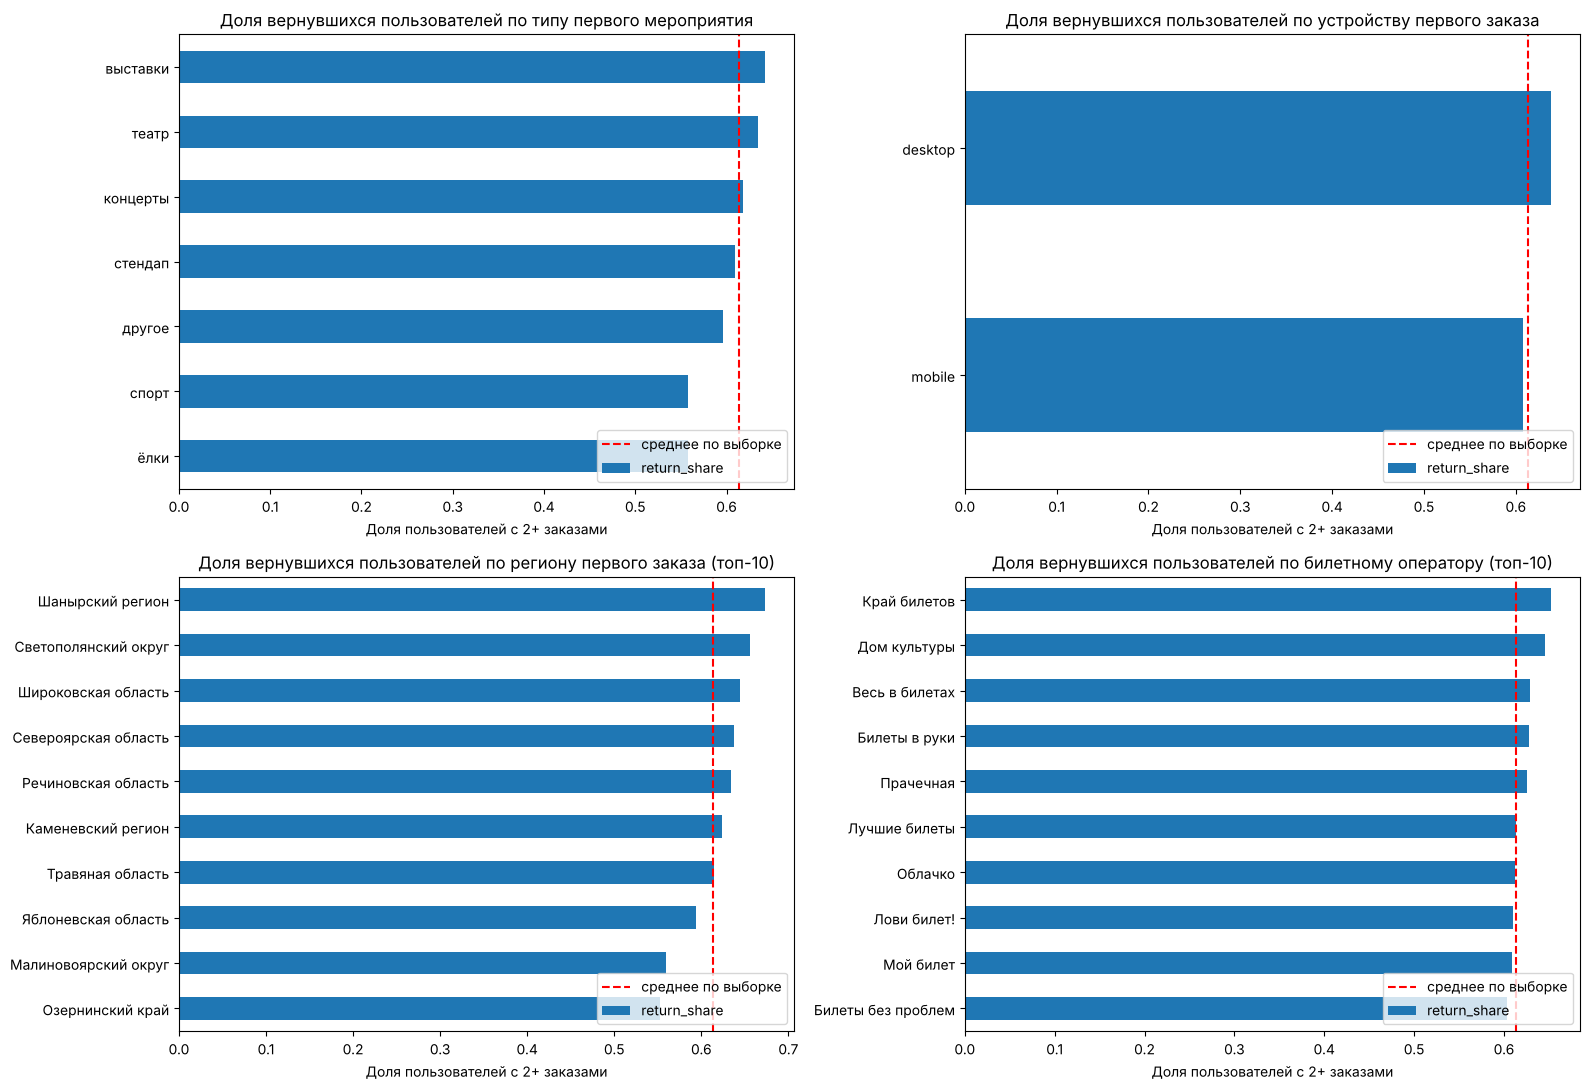

In [34]:
mean_return = profile['is_two'].mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

tables = [
    (segment_table('first_event_type'), 'типу первого мероприятия'),
    (segment_table('first_device'), 'устройству первого заказа'),
    (region_table.head(10), 'региону первого заказа (топ-10)'),
    (service_table.head(10), 'билетному оператору (топ-10)')
]

for ax, (table, name) in zip(axes.flatten(), tables):
    table['return_share'].sort_values().plot(kind='barh', ax=ax)
    ax.axvline(mean_return, color='red', linestyle='--', label='среднее по выборке')
    ax.set_title('Доля вернувшихся пользователей по ' + name)
    ax.set_xlabel('Доля пользователей с 2+ заказами')
    ax.set_ylabel('')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

В среднем 61,3% пользователей делают повторный заказ.

- **Тип мероприятия:** чаще возвращаются пользователи, начавшие с выставок (64,2%) и театра (63,4%). Концерты — на уровне среднего (61,8%). Реже возвращаются после спорта и ёлок (по 55,8%), но в сегменте «ёлки» всего 95 пользователей, поэтому его доля нестабильна.
- **Устройство:** пользователи с десктопа возвращаются немного чаще: 63,8% против 60,8% с мобильных.
- **Регион:** среди топ-10 регионов выше среднего Шанырский регион (67,3%), Светополянский округ (65,6%) и Широковская область (64,4%), ниже — Озернинский край (55,3%) и Малиновоярский округ (55,9%).
- **Билетный оператор:** выше среднего «Край билетов» (65,2%) и «Дом культуры» (64,6%), но это небольшие сегменты (350–450 человек). У крупнейшего оператора «Билеты без проблем» доля чуть ниже среднего (60,3%).

**Успешные точки входа:** первый заказ на выставку или в театр, покупка с десктопа и ряд средних по размеру регионов. Различия между сегментами в основном небольшие, 2–6 процентных пунктов.

#### 4.1.3. Проверка продуктовых гипотез

In [35]:
event_table = segment_table('first_event_type')
event_table.loc[['спорт', 'концерты']]

,users,users_share,return_share
first_event_type,,,
спорт,794,0.037,0.558
концерты,9564,0.442,0.618


**Гипотеза 1 не подтверждается.** Пользователи, начавшие со спортивных мероприятий, возвращаются **реже** (55,8%), чем начавшие с концертов (61,8%). Причём сегмент спорта небольшой (794 человека), а концертов — самый крупный (9 564).

In [36]:
region_all = segment_table('first_region')
top_regions = region_all.head(10).index

profile['region_group'] = 'остальные регионы'
profile.loc[profile['first_region'].isin(top_regions), 'region_group'] = 'топ-10 регионов'

profile.groupby('region_group').agg(users=('user_id', 'count'), return_share=('is_two', 'mean')).round(3)

,users,return_share
region_group,,
остальные регионы,6046,0.582
топ-10 регионов,15576,0.625


0.18833468992374927


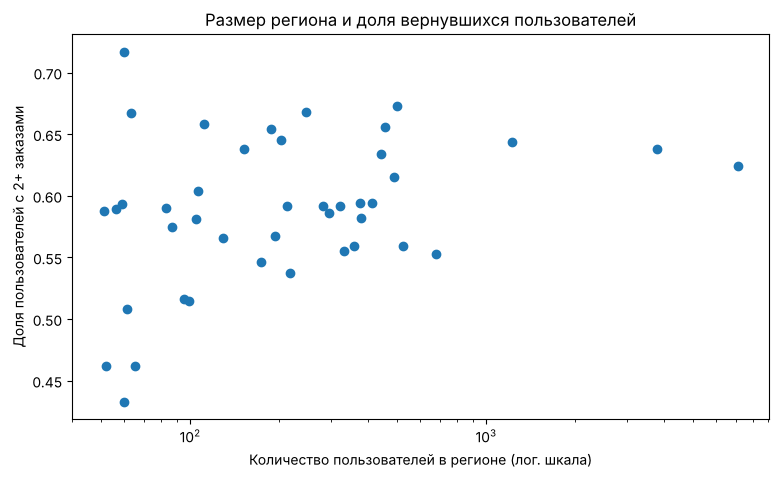

In [37]:
big_regions = region_all[region_all['users'] >= 50]
print(big_regions['users'].corr(big_regions['return_share']))

plt.figure(figsize=(9, 5))
plt.scatter(big_regions['users'], big_regions['return_share'])
plt.xscale('log')
plt.title('Размер региона и доля вернувшихся пользователей')
plt.xlabel('Количество пользователей в регионе (лог. шкала)')
plt.ylabel('Доля пользователей с 2+ заказами')
plt.show()

**Гипотеза 2 подтверждается частично.** В топ-10 регионов по числу пользователей доля повторных заказов выше, чем в остальных: 62,5% против 58,2%. Но связь слабая: корреляция между размером региона и долей вернувшихся (по регионам от 50 пользователей) — 0,19. Самые высокие доли наблюдаются не в крупнейших регионах, а в регионах среднего размера, и среди небольших регионов разброс очень большой: от 43% до 72%.

### 4.2. Выручка и состав заказа

#### 4.2.1. Средняя выручка и повторные заказы

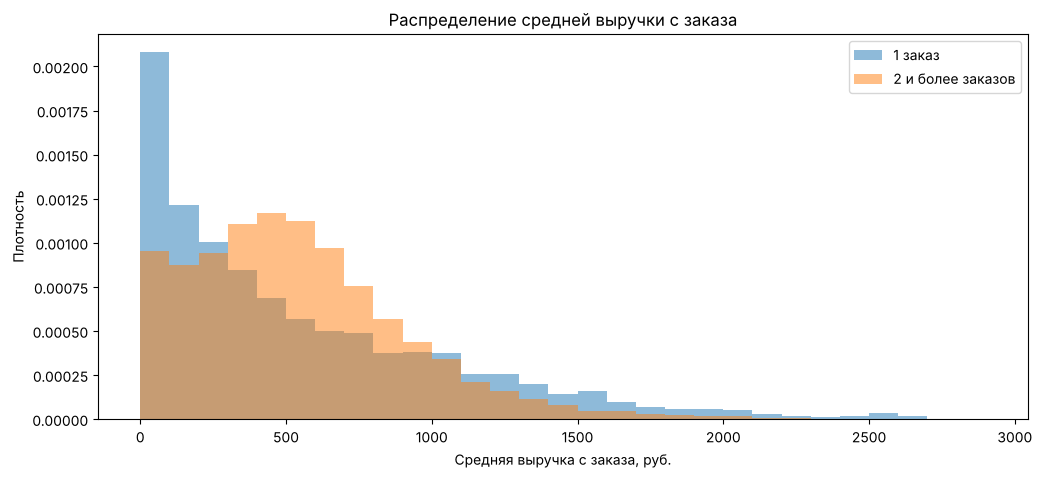

In [38]:
one_order = profile[profile['total_orders'] == 1]
returned = profile[profile['total_orders'] >= 2]

bins = range(0, 3000, 100)

plt.figure(figsize=(12, 5))
plt.hist(one_order['avg_revenue_rub'], bins=bins, alpha=0.5, density=True, label='1 заказ')
plt.hist(returned['avg_revenue_rub'], bins=bins, alpha=0.5, density=True, label='2 и более заказов')
plt.title('Распределение средней выручки с заказа')
plt.xlabel('Средняя выручка с заказа, руб.')
plt.ylabel('Плотность')
plt.legend()
plt.show()

In [39]:
pd.DataFrame({
    '1 заказ': one_order['avg_revenue_rub'].describe(),
    '2 и более заказов': returned['avg_revenue_rub'].describe()
}).round(1)

,1 заказ,2 и более заказов
count,8363.0,13259.0
mean,545.8,545.1
std,519.4,369.3
min,0.0,0.0
25%,133.1,271.7
50%,378.9,496.5
75%,831.0,745.6
max,2628.4,2628.4


У пользователей с одним заказом распределение средней выручки шире и смещено влево: пик приходится на 0–200 руб., при этом длинный хвост дорогих заказов. Медиана — 379 руб.

Вернувшиеся пользователи сосредоточены в диапазоне примерно 270–750 руб. с пиком около 400–600 руб., медиана — 497 руб. Средние значения в группах почти одинаковые (546 и 545 руб.), но у вернувшихся меньше очень дешёвых заказов. Отчасти это связано с тем, что среднее по нескольким заказам естественно ближе к центру распределения, чем выручка одного заказа.

#### 4.2.2. Пользователи с 2–4 и 5+ заказами

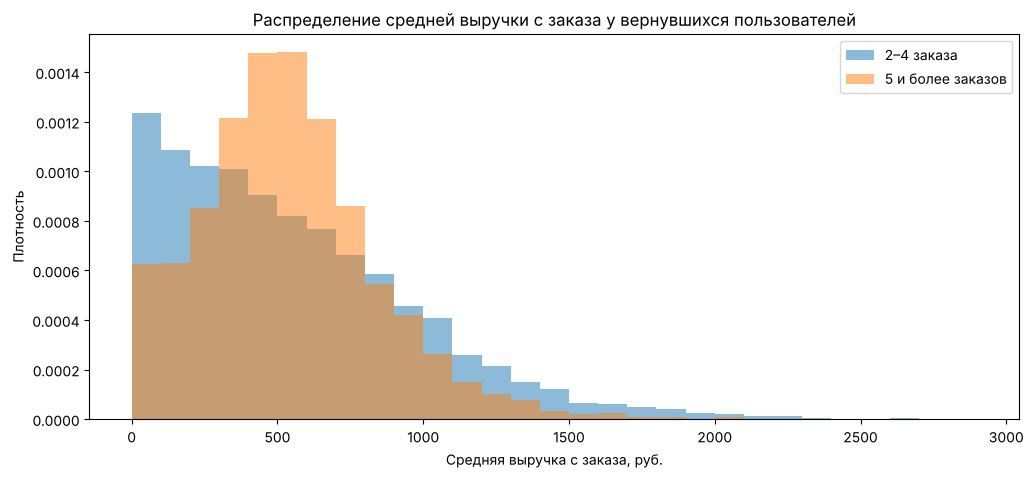

In [40]:
orders_2_4 = profile[(profile['total_orders'] >= 2) & (profile['total_orders'] <= 4)]
orders_5 = profile[profile['total_orders'] >= 5]

plt.figure(figsize=(12, 5))
plt.hist(orders_2_4['avg_revenue_rub'], bins=bins, alpha=0.5, density=True, label='2–4 заказа')
plt.hist(orders_5['avg_revenue_rub'], bins=bins, alpha=0.5, density=True, label='5 и более заказов')
plt.title('Распределение средней выручки с заказа у вернувшихся пользователей')
plt.xlabel('Средняя выручка с заказа, руб.')
plt.ylabel('Плотность')
plt.legend()
plt.show()

In [41]:
pd.DataFrame({
    '2–4 заказа': orders_2_4['avg_revenue_rub'].describe(),
    '5 и более заказов': orders_5['avg_revenue_rub'].describe()
}).round(1)

,2–4 заказа,5 и более заказов
count,7143.0,6116.0
mean,552.3,536.6
std,420.1,299.0
min,0.0,0.0
25%,219.6,331.7
50%,472.5,513.3
75%,799.3,701.0
max,2628.4,2299.9


Средняя выручка в группах почти не отличается: 552 руб. у пользователей с 2–4 заказами и 537 руб. у пользователей с 5 и более заказами. Медиана у второй группы немного выше (513 против 473 руб.), а разброс заметно меньше: большинство пользователей с 5+ заказами тратят 330–700 руб. за заказ. Существенной разницы в уровне средней выручки между группами нет, у частых покупателей она просто стабильнее.

#### 4.2.3. Среднее количество билетов и повторные покупки

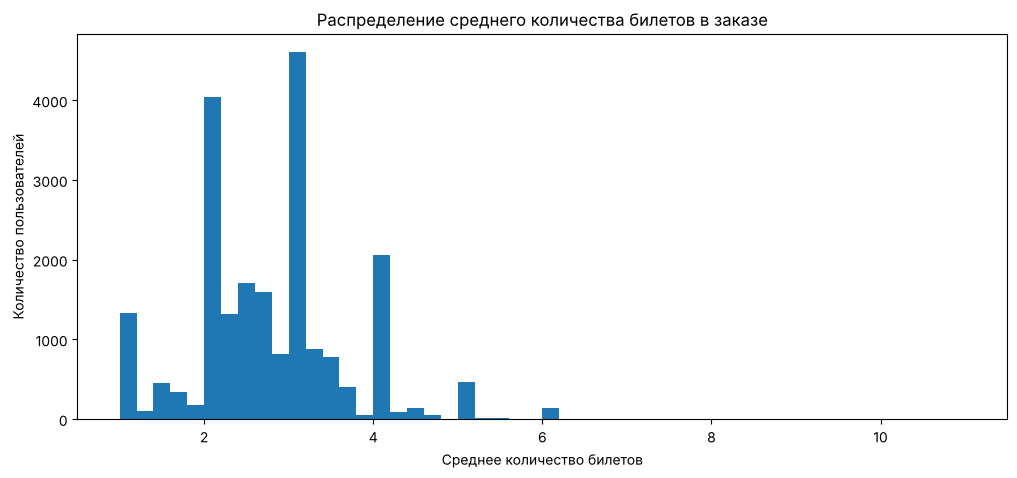

count    21622.000000
mean         2.744265
std          0.917489
min          1.000000
25%          2.000000
50%          2.750000
75%          3.100000
max         11.000000
Name: avg_tickets_count, dtype: float64

In [42]:
plt.figure(figsize=(12, 5))
profile['avg_tickets_count'].plot(kind='hist', bins=50)
plt.title('Распределение среднего количества билетов в заказе')
plt.xlabel('Среднее количество билетов')
plt.ylabel('Количество пользователей')
plt.show()

profile['avg_tickets_count'].describe()

In [43]:
profile['tickets_segment'] = pd.cut(
    profile['avg_tickets_count'],
    bins=[1, 2, 3, 5, profile['avg_tickets_count'].max() + 1],
    labels=['от 1 до 2', 'от 2 до 3', 'от 3 до 5', '5 и более'],
    right=False
)

tickets_table = profile.groupby('tickets_segment', observed=True).agg(users=('user_id', 'count'), return_share=('is_two', 'mean'))
tickets_table['users_share'] = tickets_table['users'] / tickets_table['users'].sum()
tickets_table.round(3)

,users,return_share,users_share
tickets_segment,,,
от 1 до 2,2410,0.512,0.111
от 2 до 3,9487,0.736,0.439
от 3 до 5,9064,0.543,0.419
5 и более,661,0.188,0.031


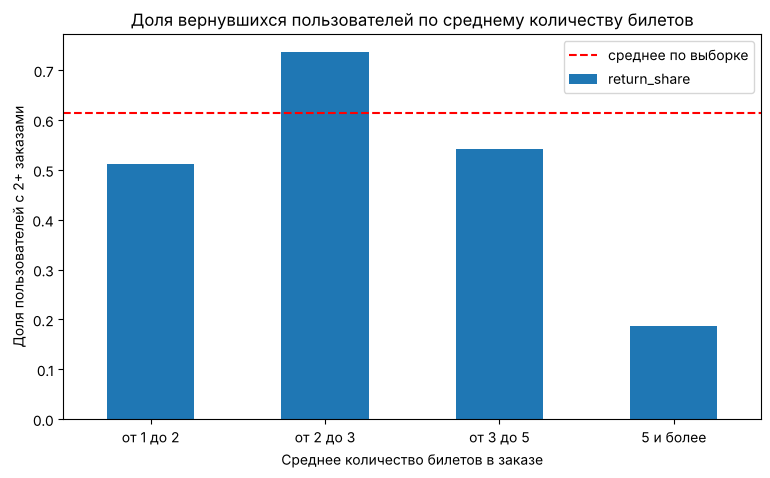

In [44]:
tickets_table['return_share'].plot(kind='bar', figsize=(9, 5), rot=0)
plt.axhline(mean_return, color='red', linestyle='--', label='среднее по выборке')
plt.title('Доля вернувшихся пользователей по среднему количеству билетов')
plt.xlabel('Среднее количество билетов в заказе')
plt.ylabel('Доля пользователей с 2+ заказами')
plt.legend()
plt.show()

Среднее количество билетов в заказе — 2,74, медиана — 2,75. Распределение сконцентрировано: 86% пользователей покупают в среднем от 2 до 5 билетов, заметны пики на значениях 2, 3 и 4.

- **от 1 до 2 билетов** — 11% пользователей, повторно покупают 51%;
- **от 2 до 3 билетов** — 44% пользователей, повторно покупают **74%**, это заметно выше среднего (61%);
- **от 3 до 5 билетов** — 42% пользователей, повторно покупают 54%;
- **5 и более билетов** — 3% пользователей, повторно покупают всего **19%**, аномально низкая доля.

Чаще всего возвращаются пользователи, которые покупают 2–3 билета (например, на пару или маленькую компанию). Крупные групповые покупки чаще оказываются разовыми.

### 4.3. Временные характеристики первого заказа

#### 4.3.1. День недели первой покупки

In [45]:
days = ['понедельник', 'вторник', 'среда', 'четверг', 'пятница', 'суббота', 'воскресенье']

profile['first_weekday'] = profile['first_dt'].dt.weekday

weekday_table = profile.groupby('first_weekday').agg(users=('user_id', 'count'), return_share=('is_two', 'mean'))
weekday_table.index = days
weekday_table.round(3)

,users,return_share
понедельник,2918,0.630
вторник,3175,0.619
среда,3061,0.623
четверг,3112,0.594
пятница,3256,0.598
суббота,3323,0.628
воскресенье,2777,0.601


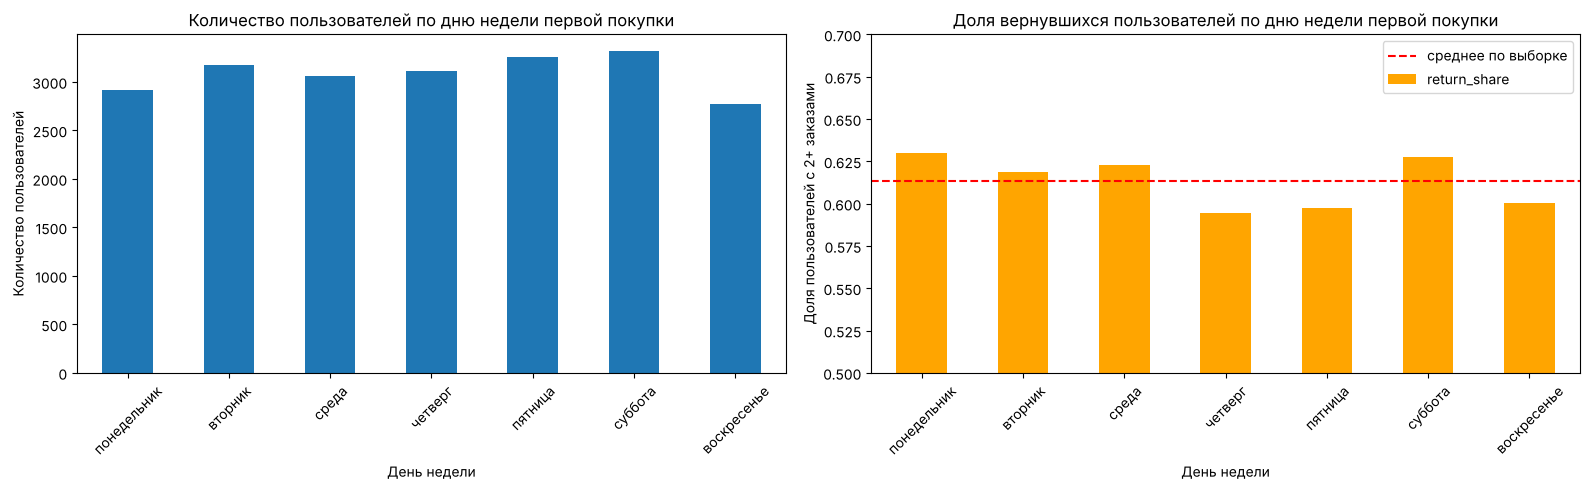

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

weekday_table['users'].plot(kind='bar', ax=axes[0], rot=45)
axes[0].set_title('Количество пользователей по дню недели первой покупки')
axes[0].set_xlabel('День недели')
axes[0].set_ylabel('Количество пользователей')

weekday_table['return_share'].plot(kind='bar', ax=axes[1], rot=45, color='orange')
axes[1].axhline(mean_return, color='red', linestyle='--', label='среднее по выборке')
axes[1].set_title('Доля вернувшихся пользователей по дню недели первой покупки')
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Доля пользователей с 2+ заказами')
axes[1].set_ylim(0.5, 0.7)
axes[1].legend()

plt.tight_layout()
plt.show()

Первые покупки распределены по дням недели равномерно: от 2 777 (воскресенье) до 3 323 (суббота). Доля вернувшихся меняется от 59,4% (четверг) до 63,0% (понедельник), то есть разброс около 3,6 процентного пункта. Явной зависимости нет: день недели первой покупки практически не влияет на вероятность возврата.

#### 4.3.2. Средний интервал между заказами

In [47]:
pd.DataFrame({
    '2–4 заказа': orders_2_4['avg_days_since_prev'].describe(),
    '5 и более заказов': orders_5['avg_days_since_prev'].describe()
}).round(1)

,2–4 заказа,5 и более заказов
count,7143.0,6116.0
mean,21.3,9.9
std,28.5,7.8
min,0.0,0.0
25%,0.0,3.9
50%,9.0,8.1
75%,34.0,14.1
max,148.0,37.5


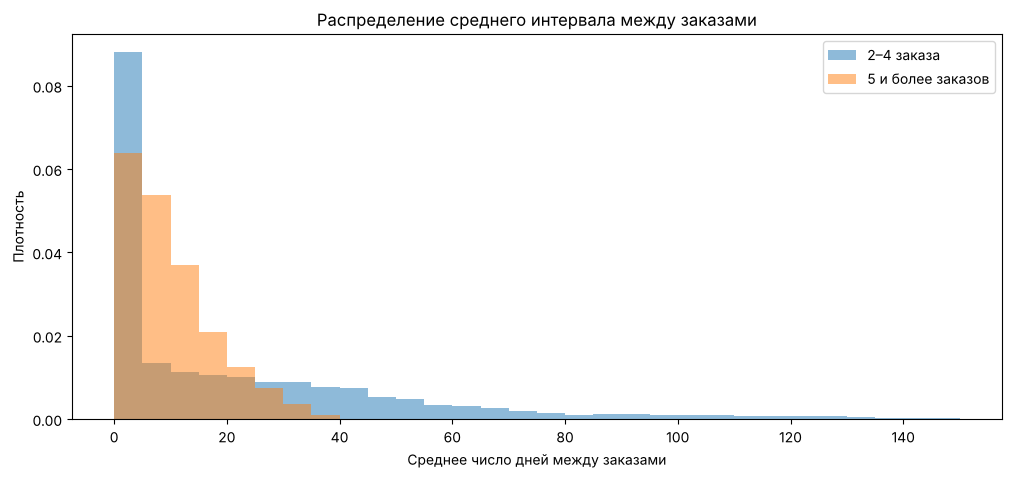

In [48]:
plt.figure(figsize=(12, 5))
plt.hist(orders_2_4['avg_days_since_prev'], bins=range(0, 155, 5), alpha=0.5, density=True, label='2–4 заказа')
plt.hist(orders_5['avg_days_since_prev'], bins=range(0, 155, 5), alpha=0.5, density=True, label='5 и более заказов')
plt.title('Распределение среднего интервала между заказами')
plt.xlabel('Среднее число дней между заказами')
plt.ylabel('Плотность')
plt.legend()
plt.show()

In [49]:
returned = profile[profile['total_orders'] >= 2].copy()
returned['days_segment'] = pd.cut(
    returned['avg_days_since_prev'],
    bins=[0, 7, 14, 30, 60, 160],
    labels=['до недели', '1–2 недели', '2 недели – месяц', '1–2 месяца', 'более 2 месяцев'],
    include_lowest=True
)
returned.groupby('days_segment', observed=True).agg(users=('user_id', 'count'), share_five=('is_five', 'mean')).round(3)

,users,share_five
days_segment,,
до недели,6101,0.445
1–2 недели,2475,0.756
2 недели – месяц,2539,0.551
1–2 месяца,1448,0.090
более 2 месяцев,696,0.000


У пользователей с 5 и более заказами средний интервал между покупками — 9,9 дня (медиана 8,1, максимум 37,5). У пользователей с 2–4 заказами — 21,3 дня (медиана 9), и разброс намного больше: у части из них два заказа сделаны в один день, а у части интервал больше 2 месяцев.

Среди вернувшихся пользователей до 5 и более заказов чаще всего доходят те, кто покупает раз в 1–2 недели (76%). При интервале от 2 недель до месяца таких 55%, а при интервале 1–2 месяца — только 9%. Частые покупки в один и тот же день (интервал до недели) тоже реже приводят к 5+ заказам (45%): часто это несколько заказов на одно событие.

Нужно учитывать, что данные охватывают всего 5 месяцев, поэтому при большом интервале пользователь физически не успевает сделать много заказов. Тем не менее регулярные покупки раз в 1–2 недели — признак самых лояльных клиентов.

### 4.4. Корреляционный анализ

In [50]:
corr_cols = ['total_orders', 'first_device', 'first_region', 'first_service', 'first_event_type',
             'avg_revenue_rub', 'avg_tickets_count', 'avg_days_since_prev', 'first_weekday']

corr = profile[corr_cols].phik_matrix(interval_cols=['total_orders', 'avg_revenue_rub', 'avg_tickets_count', 'avg_days_since_prev'])
corr[['total_orders']].drop('total_orders').sort_values(by='total_orders', ascending=False)

,total_orders
avg_days_since_prev,0.284260
avg_tickets_count,0.225326
avg_revenue_rub,0.219467
first_region,0.117162
first_weekday,0.059635
first_service,0.028571
first_event_type,0.028444
first_device,0.026483


In [51]:
print(profile['total_orders'].value_counts().head(10))

total_orders
1     8363
2     3571
3     2172
4     1400
5      969
6      702
7      541
8      454
9      384
10     287
Name: count, dtype: int64


In [52]:
profile['orders_segment'] = pd.cut(
    profile['total_orders'],
    bins=[0, 1, 4, profile['total_orders'].max()],
    labels=['1 заказ', '2–4 заказа', '5 и более']
)
profile['orders_segment'].value_counts()

orders_segment
1 заказ       8363
2–4 заказа    7143
5 и более     6116
Name: count, dtype: int64

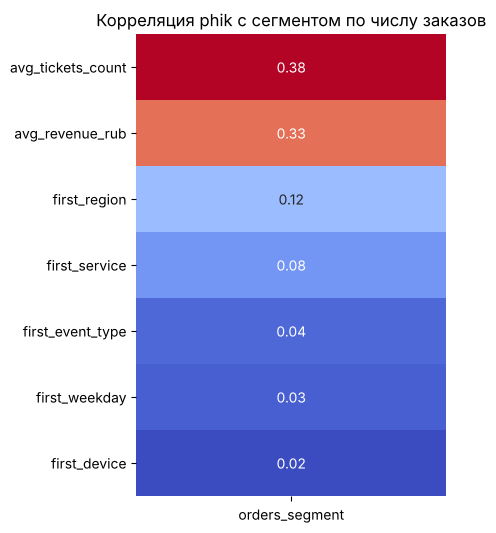

,orders_segment
avg_tickets_count,0.383
avg_revenue_rub,0.325
first_region,0.124
first_service,0.082
first_event_type,0.041
first_weekday,0.033
first_device,0.017


In [53]:
corr_cols = ['orders_segment', 'first_device', 'first_region', 'first_service', 'first_event_type',
             'avg_revenue_rub', 'avg_tickets_count', 'first_weekday']

corr_segment = profile[corr_cols].phik_matrix(interval_cols=['avg_revenue_rub', 'avg_tickets_count'])
segment_corr = corr_segment[['orders_segment']].drop('orders_segment').sort_values(by='orders_segment', ascending=False)

plt.figure(figsize=(4, 6))
sns.heatmap(segment_corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=False)
plt.title('Корреляция phik с сегментом по числу заказов')
plt.show()

segment_corr.round(3)

In [54]:
profile.groupby('orders_segment', observed=True)['avg_tickets_count'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
orders_segment,,,,,,,,
1 заказ,8363.0,2.76,1.16,1.0,2.0,3.00,4.00,11.00
2–4 заказа,7143.0,2.74,0.85,1.0,2.0,2.67,3.33,9.00
5 и более,6116.0,2.73,0.54,1.0,2.4,2.71,3.00,6.57


По всем пользователям связь числа заказов со всеми признаками слабая. Сильнее всего `total_orders` связан со средним интервалом между заказами (0,28), количеством билетов (0,23) и выручкой (0,22). Связь с регионом — 0,12, с остальными признаками первого заказа — меньше 0,06.

В `total_orders` преобладают небольшие значения (39% пользователей сделали 1 заказ), поэтому повторили анализ для сегментов: 1 заказ, 2–4 заказа и 5 и более. Средний интервал между заказами здесь не используется, так как у пользователей с одним заказом его нет.

С сегментом по числу заказов сильнее всего связаны **среднее количество билетов в заказе (0,38)** и **средняя выручка с заказа (0,33)**. Связь умеренная. Слабая связь есть с регионом (0,12) и билетным оператором (0,08). Тип первого мероприятия, день недели и устройство с числом заказов практически не связаны (меньше 0,05).

Пользователи с 5 и более заказами покупают в среднем столько же билетов (2,73), но гораздо стабильнее (стандартное отклонение 0,54 против 1,16 у пользователей с одним заказом).

## 5. Общие выводы и рекомендации

**Данные и подготовка.** Проанализировано 290 611 заказов Яндекс Афиши за июнь–октябрь 2024 года с мобильных и десктопных устройств, без заказов на фильмы. Выручка в тенге (1,7% заказов) пересчитана в рубли по курсу на дату заказа. Удалено 30 дубликатов и заказы с отрицательной выручкой или выручкой выше 99-го перцентиля (2 628 руб.) — всего 1,1% строк. При построении профилей исключены 216 пользователей (1%) с аномально большим числом заказов (больше 152, до 10 тыс. за 5 месяцев).

**Основные результаты:**
- В выборке 21 622 пользователя. 39% сделали один заказ, 61% вернулись за повторным заказом, 28% сделали 5 и более заказов. Медиана — 2 заказа, средняя выручка с заказа — около 545 руб., в среднем 2,7 билета в заказе, средний интервал между заказами — 16 дней.
- **Признаки первого заказа** связаны с возвратом слабо. Чаще возвращаются пользователи, начавшие с выставок (64%) и театра (63%), и покупавшие с десктопа (64% против 61% с мобильных). Реже — после спорта и ёлок (56%). Гипотеза о том, что любители спорта возвращаются чаще любителей концертов, **не подтвердилась**. Гипотеза о более высокой доле повторных заказов в крупных регионах подтвердилась **частично**: в топ-10 регионов 62,5% против 58,2%, но связь слабая.
- **Выручка:** средняя выручка у разовых и вернувшихся пользователей одинаковая (около 545 руб.), но у разовых больше очень дешёвых заказов, а у постоянных выручка стабильнее и сосредоточена в диапазоне 300–750 руб.
- **Количество билетов** — самый заметный признак. Пользователи, покупающие в среднем 2–3 билета, возвращаются в 74% случаев, а покупающие 5 и более билетов — только в 19%.
- **Время:** день недели первой покупки на возврат не влияет. Самые лояльные пользователи (5+ заказов) покупают регулярно, в среднем раз в 8–10 дней.
- **Корреляционный анализ:** с числом заказов сильнее всего связаны среднее количество билетов (phik 0,38) и средняя выручка с заказа (0,33). Регион и оператор связаны слабо, устройство, тип мероприятия и день недели — практически не связаны.

**Рекомендации:**
1. Сделать основным сегментом для удержания пользователей, покупающих 2–3 билета: они возвращаются чаще всех. Им стоит предлагать персональные подборки мероприятий и бонусы за следующий заказ.
2. Пользователей с крупными групповыми заказами (5+ билетов) считать разовыми. Если их нужно удерживать, лучше использовать отдельные предложения для групп и компаний.
3. Использовать выставки и театр как точку входа в рекламе: такие пользователи возвращаются чаще. Для новичков из сегментов спорта и ёлок нужны дополнительные стимулы к повторной покупке, например рекомендации других типов мероприятий после первого заказа.
4. Мобильное приложение — главная точка входа (83% пользователей), но возвращаются с него реже, чем с десктопа. Стоит проверить удобство повторной покупки в приложении.
5. Напоминать пользователям о новых мероприятиях примерно через 1–2 недели после покупки: именно с таким интервалом покупают самые лояльные клиенты.
6. Не тратить ресурсы на настройку рекламы по дню недели первой покупки: он на возврат не влияет.

## 6. Финализация проекта и публикация в Git

Ссылка на репозиторий: https://github.com/mishailN17noname/yandex-afisha-loyalty-analysis